Q1. Student Performance and Correlation Analysis
A college collects data on students' study hours, attendance, and examination marks.

(a) Create scatter plots for Study Hours vs Marks and Attendance vs Marks in separate subplots. Calculate Pearson's correlation coefficient for both pairs and determine which feature has the stronger linear association with marks. Support your conclusion with the correlation values.

(b) Add a hypothetical student with 1 study hour, 95% attendance, and 98 marks. Recalculate both correlations and visualize the updated data. Explain how this observation affects the correlation coefficients and why a single unusual observation can influence statistical conclusions.

In [144]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({    "Study_Hours": [ 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 2, 4, 6, 8, 3    ],   
 "Attendance": [ 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 58, 68, 78, 88, 62    ], 
   "Marks": [ 30, 35, 45, 50, 60, 65, 75, 82, 90, 98,  38, 52, 68, 85, 42    ]})

In [145]:
df

,Study_Hours,Attendance,Marks
0,1,50,30
1,2,55,35
2,3,60,45
3,4,65,50
4,5,70,60
5,6,75,65
6,7,80,75
7,8,85,82
8,9,90,90
9,10,95,98


Text(0.5, 1.0, 'Study Hours vs Marks')

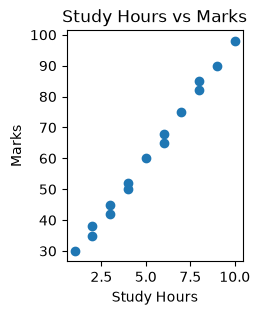

In [146]:
plt.figure(figsize=(5,3))

plt.subplot(1, 2, 1)
plt.scatter(df["Study_Hours"], df["Marks"])
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Marks")



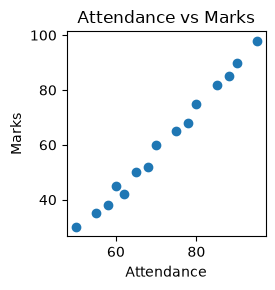

In [147]:
plt.figure(figsize=(5,3))
plt.subplot(1, 2, 2)
plt.scatter(df["Attendance"], df["Marks"])
plt.xlabel("Attendance")
plt.ylabel("Marks")
plt.title("Attendance vs Marks")
plt.tight_layout()
plt.show()

In [148]:
df

,Study_Hours,Attendance,Marks
0,1,50,30
1,2,55,35
2,3,60,45
3,4,65,50
4,5,70,60
5,6,75,65
6,7,80,75
7,8,85,82
8,9,90,90
9,10,95,98


In [149]:
new_student = pd.DataFrame({
    "Study_Hours": [1],
    "Attendance": [95],
    "Marks": [98]
})


In [150]:
new_student

,Study_Hours,Attendance,Marks
0,1,95,98


In [151]:
df = pd.concat([df, new_student], ignore_index=True)


In [152]:
df

,Study_Hours,Attendance,Marks
0,1,50,30
1,2,55,35
2,3,60,45
3,4,65,50
4,5,70,60
5,6,75,65
6,7,80,75
7,8,85,82
8,9,90,90
9,10,95,98


In [153]:
corr1 = df["Study_Hours"].corr(df["Marks"])
corr2 = df["Attendance"].corr(df["Marks"])


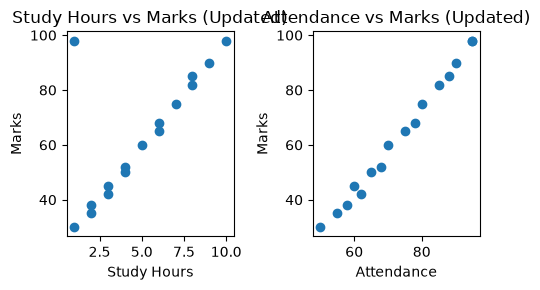

In [154]:
plt.figure(figsize=(5,3))
plt.subplot(1, 2, 1)
plt.scatter(df["Study_Hours"], df["Marks"])
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Marks (Updated)")

plt.subplot(1, 2, 2)
plt.scatter(df["Attendance"], df["Marks"])
plt.xlabel("Attendance")
plt.ylabel("Marks")
plt.title("Attendance vs Marks (Updated)")
plt.tight_layout()
plt.show()

Q2. Product Sales: Bar Plot and Business Decisions
An electronics store records its sales and revenue across six products.

(a) Create a figure containing two bar plots comparing Units Sold and Revenue by product. Identify the highest and lowest products for each metric, calculate each product's percentage contribution to total revenue, and explain why the product with the highest unit sales may not generate the highest revenue.

(b) Calculate revenue per unit for every product and create a bar plot ranking products by this metric. Use Python to identify products with high unit sales but comparatively low revenue per unit, and recommend how the store should interpret these three metrics together.

In [155]:

df = pd.DataFrame({"Product": ["Laptop", "Mobile", "Tablet", "Headphones", "Monitor", "Keyboard"    ],  
  "Units_Sold": [45, 120, 60, 90, 35, 100],    
"Revenue": [2250000, 1800000, 600000, 270000, 525000, 200000]})

In [156]:
df["Revenue"].sum()

np.int64(5645000)

In [157]:
total_revenue = df["Revenue"].sum()

In [158]:
total_revenue

np.int64(5645000)

In [159]:
(df["Revenue"] / total_revenue) * 100

0    39.858282
1    31.886625
2    10.628875
3     4.782994
4     9.300266
5     3.542958
Name: Revenue, dtype: float64

In [160]:
df["Revenue_Percentage"] = (df["Revenue"] / total_revenue) * 100

([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'Laptop'),
  Text(1, 0, 'Mobile'),
  Text(2, 0, 'Tablet'),
  Text(3, 0, 'Headphones'),
  Text(4, 0, 'Monitor'),
  Text(5, 0, 'Keyboard')])

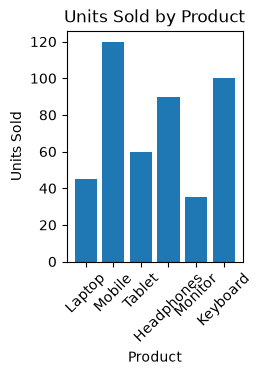

In [161]:
plt.figure(figsize=(5,3))

plt.subplot(1, 2, 1)
plt.bar(df["Product"], df["Units_Sold"])
plt.xlabel("Product")
plt.ylabel("Units Sold")
plt.title("Units Sold by Product")
plt.xticks(rotation=45)

In [162]:

 df["Revenue"] / df["Units_Sold"]


0    50000.0
1    15000.0
2    10000.0
3     3000.0
4    15000.0
5     2000.0
dtype: float64

In [163]:

df["Revenue_Per_Unit"] = df["Revenue"] / df["Units_Sold"]


In [164]:
df = df.sort_values("Revenue_Per_Unit", ascending=False)

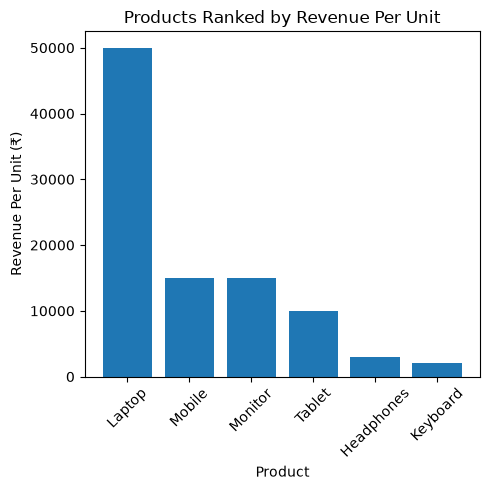

In [165]:
plt.figure(figsize=(5,5))
plt.bar(df["Product"], df["Revenue_Per_Unit"])
plt.xlabel("Product")
plt.ylabel("Revenue Per Unit (₹)")
plt.title("Products Ranked by Revenue Per Unit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [166]:
high_sales_low_revenue = df[
    (df["Units_Sold"] >= 90) &
    (df["Revenue_Per_Unit"] < df["Revenue_Per_Unit"].median())
]


In [167]:
high_sales_low_revenue 

,Product,Units_Sold,Revenue,Revenue_Percentage,Revenue_Per_Unit
3,Headphones,90,270000,4.782994,3000.0
5,Keyboard,100,200000,3.542958,2000.0


(a) Create scatter plots for total_bill vs tip and size vs tip. Calculate the Pearson correlation coefficients for both relationships. Identify which pair has the stronger linear association and explain how the scatter plots support or challenge the numerical results.

(b) Group the dataset by party size and calculate the average tip for each group. Create a bar plot of the average tip by party size, then compare the pattern in the grouped bar plot with the correlation between size and tip. Explain why grouped averages and individual-level correlation can tell different stories.

In [168]:
import seaborn as sns

In [169]:
df = sns.load_dataset('tips')

In [170]:
corr1 = df["total_bill"].corr(df["tip"])
corr2 = df["size"].corr(df["tip"])


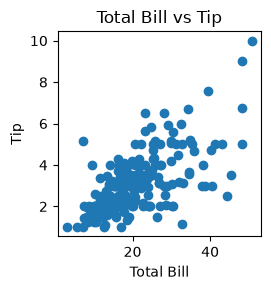

In [171]:
plt.figure(figsize=(5,3))
plt.subplot(1, 2, 1)
plt.scatter(df["total_bill"], df["tip"])
plt.xlabel("Total Bill")
plt.ylabel("Tip")
plt.title("Total Bill vs Tip")
plt.tight_layout()
plt.show()

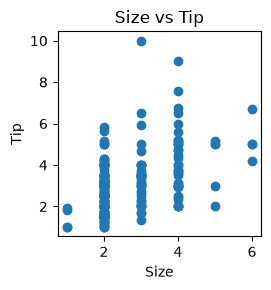

In [172]:
plt.figure(figsize=(5,3))
plt.subplot(1, 2, 2)
plt.scatter(df["size"], df["tip"])
plt.xlabel("Size")
plt.ylabel("Tip")
plt.title("Size vs Tip")
plt.tight_layout()
plt.show()

In [173]:
df = sns.load_dataset("tips")


In [174]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [175]:

avg_tip = df.groupby("size", observed=True)["tip"].mean()

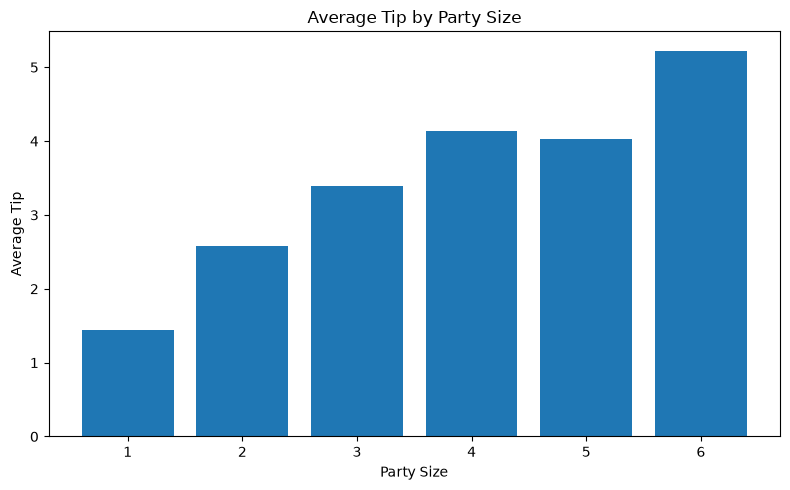

In [176]:
plt.figure(figsize=(8, 5))
plt.bar(avg_tip.index, avg_tip.values)
plt.xlabel("Party Size")
plt.ylabel("Average Tip")
plt.title("Average Tip by Party Size")
plt.tight_layout()
plt.show()

In [177]:
corr = df["size"].corr(df["tip"])

In [178]:
corr

np.float64(0.4892987752303579)

4. Comparing Positive, Negative, and Weak Correlations
A marketing analyst investigates advertising expenditure and sales across different campaigns.

(a) Create scatter plots for Advertising Cost vs Sales and Advertising Cost vs Customer Satisfaction. Calculate both Pearson correlation coefficients, classify each relationship as positive, negative, or weak, and justify your classifications using numerical evidence.

(b) Add a new campaign with an advertising cost of 100 and sales of 200. Recalculate the correlation between advertising cost and sales, plot the new point, and explain why correlation does not establish causation or guarantee that increased advertising will produce increased sales

In [179]:
df = pd.DataFrame({"Campaign": [ "A", "B", "C", "D", "E", "F", "G", "H", "I", "J"    ],   
 "Advertising_Cost": [        10, 15, 20, 25, 30, 35, 40, 45, 50, 55    ],    
"Sales": [ 90, 80, 75, 70, 65, 60, 55, 50, 45, 40    ],    
"Customer_Satisfaction": [ 60, 75, 55, 85, 65, 70, 50, 80, 60, 75    ]})

In [180]:
df

,Campaign,Advertising_Cost,Sales,Customer_Satisfaction
0,A,10,90,60
1,B,15,80,75
2,C,20,75,55
3,D,25,70,85
4,E,30,65,65
5,F,35,60,70
6,G,40,55,50
7,H,45,50,80
8,I,50,45,60
9,J,55,40,75


In [181]:
corr1 = df["Advertising_Cost"].corr(df["Sales"])
corr2 = df["Advertising_Cost"].corr(df["Customer_Satisfaction"])

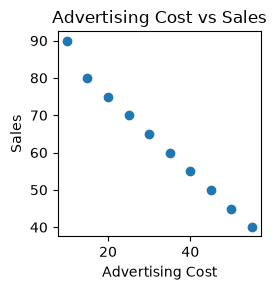

In [182]:
plt.figure(figsize=(5,3))
plt.subplot(1, 2, 1)
plt.scatter(df["Advertising_Cost"], df["Sales"])
plt.xlabel("Advertising Cost")
plt.ylabel("Sales")
plt.title("Advertising Cost vs Sales")
plt.tight_layout()
plt.show()

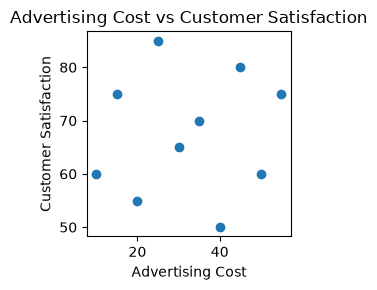

In [183]:
plt.figure(figsize=(5,3))
plt.subplot(1, 2, 2)
plt.scatter(df["Advertising_Cost"], df["Customer_Satisfaction"])
plt.xlabel("Advertising Cost")
plt.ylabel("Customer Satisfaction")
plt.title("Advertising Cost vs Customer Satisfaction")
plt.tight_layout()
plt.show()

In [184]:
df["Advertising_Cost"].corr(df["Sales"])


np.float64(-0.996451792478872)

In [185]:
original_corr = df["Advertising_Cost"].corr(df["Sales"])


In [186]:
new_campaign = pd.DataFrame({
    "Campaign": ["K"],
    "Advertising_Cost": [100],
    "Sales": [200]
})


In [187]:
df = pd.concat([df, new_campaign], ignore_index=True)

In [188]:
updated_corr = df["Advertising_Cost"].corr(df["Sales"])

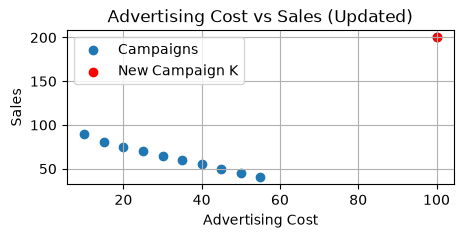

In [189]:
plt.figure(figsize=(5,2))
plt.scatter(df["Advertising_Cost"], df["Sales"], label="Campaigns")
plt.scatter(100, 200, color="red", label="New Campaign K")
plt.xlabel("Advertising Cost")
plt.ylabel("Sales")
plt.title("Advertising Cost vs Sales (Updated)")
plt.legend()
plt.grid(True)
plt.show()
